### Analisis dan Regresi Nilai Tukar Rupiah (USD/IDR) Menggunakan Harga Emas, Indeks Dolar, dan IHSG

Nama:Syafiatul Adawiah

Nim :E1E124017

###  Menentukan Pertanyaan Bisnis

1. Bagaimana pola pergerakan nilai tukar Rupiah (USD/IDR) selama periode penelitian?
2. Bagaimana hubungan harga emas, USD Index, dan IHSG terhadap nilai tukar Rupiah?
3. Variabel manakah yang memiliki hubungan paling kuat terhadap pergerakan nilai tukar Rupiah?
4. Seberapa baik model machine learning dapat memprediksi nilai tukar Rupiah periode berikutnya?

### Import Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pg8000.dbapi as pg8000driver
import xgboost as xgb

from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
plt.style.use("seaborn-v0_8")

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


## Data Wrangling

### Gathering Data

#### Tabel 1: Currency

In [66]:
conn = pg8000driver.connect(
    user="postgres",
    password="postgres",
    host="localhost",
    port=5432,
    database="postgres"
)

In [67]:
df_currency = pd.read_sql_query(
    "SELECT * FROM currency.daily_rates ORDER BY date",
    conn
)

print(df_currency.shape)
print(df_currency["date"].min())
print(df_currency["date"].max())

df_currency.tail()

(183, 6)
2026-03-28
2026-10-05


C:\Users\My ASUS\AppData\Local\Temp\ipykernel_27624\3069883184.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_currency = pd.read_sql_query(


,date,idr,myr,sgd,thb,php
178,2026-09-27,17896.543089,4.074610,1.277626,33.426567,62.456279
179,2026-09-28,17951.684356,4.081996,1.277802,33.569704,62.453982
180,2026-09-29,18016.343107,4.083235,1.278658,33.633025,62.517539
181,2026-10-03,17880.361409,4.084839,1.279360,33.532694,62.511629
182,2026-10-05,17941.405273,4.088019,1.281879,33.688332,62.741798


#### Tabel 2: Gold

In [68]:
df_gold = pd.read_sql_query(
    "SELECT * FROM commodity.gold_price ORDER BY date",
    conn
)

print(df_gold.shape)
print(df_gold["date"].min())
print(df_gold["date"].max())

df_gold.tail()

(183, 3)
2026-03-28
2026-10-05


C:\Users\My ASUS\AppData\Local\Temp\ipykernel_27624\3654411350.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_gold = pd.read_sql_query(


,date,xau_per_usd,gold_usd_per_ounce
178,2026-09-27,0.000233,4286.142900
179,2026-09-28,0.000238,4198.341403
180,2026-09-29,0.000242,4129.100455
181,2026-10-03,0.000242,4137.545244
182,2026-10-05,0.000242,4131.879683


#### Tabel 3: USD Index

In [69]:
df_usd = pd.read_sql_query(
    "SELECT * FROM market.usd_index ORDER BY date",
    conn
)

print(df_usd.shape)
print(df_usd["date"].min())
print(df_usd["date"].max())

df_usd.tail()

(249, 2)
2025-10-06
2026-10-02


C:\Users\My ASUS\AppData\Local\Temp\ipykernel_27624\2504799714.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_usd = pd.read_sql_query(


,date,usd_index
244,2026-09-28,120.6958
245,2026-09-29,121.0296
246,2026-09-30,120.9693
247,2026-10-01,121.7882
248,2026-10-02,121.3848


#### Tabel 4: IHSG

In [70]:
df_ihsg = pd.read_sql("SELECT * FROM market.ihsg", conn)
print(df_ihsg.shape)
df_ihsg.tail()

(240, 6)


C:\Users\My ASUS\AppData\Local\Temp\ipykernel_27624\2693474273.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_ihsg = pd.read_sql("SELECT * FROM market.ihsg", conn)


,date,open,high,low,close,volume
235,2026-09-28,6209.746094,6227.898926,6140.341797,6147.858887,287430500
236,2026-09-29,6118.806152,6150.551758,6013.079102,6121.700195,340052700
237,2026-09-30,6118.047852,6187.045898,6071.138184,6071.138184,267762500
238,2026-10-01,6062.894043,6095.233887,5973.163086,6009.501953,293469300
239,2026-10-02,6018.081055,6053.235840,5979.982910,6036.888184,1155071900


### Insight Raw Data

* IHSG: Data yang diperoleh berupa data perdagangan saham harian, meliputi nilai open, high, low, close, dan volume.
* USD Index:Data indeks dolar AS berhasil diperoleh secara berkala melalui sumber API.
* Gold: Data yang dikumpulkan berupa harga emas dalam satuan USD per ounce dan diperbarui secara otomatis.
* Currency: Data mencakup nilai tukar USD terhadap IDR, MYR, SGD, THB, dan PHP.
* Otomatisasi:Proses pengambilan seluruh data dijalankan menggunakan Airflow dengan jadwal.
* Format: Hasil ekstraksi disimpan terlebih dahulu dalam format JSON sebagai data mentah sebelum diproses pada tahap transformasi.


## Assessing Data 

Assessing Data — currency.daily_rates

1. Kelengkapan Data

In [71]:
print("Jumlah baris:", len(df_currency))
print("Jumlah kolom:", len(df_currency.columns))
print("Data kosong:", df_currency.empty)

Jumlah baris: 183
Jumlah kolom: 6
Data kosong: False


2. Struktur Data

In [72]:
print("Nama kolom:")
print(df_currency.columns.tolist())

print("\nTipe data:")
print(df_currency.dtypes)

Nama kolom:
['date', 'idr', 'myr', 'sgd', 'thb', 'php']

Tipe data:
date     object
idr     float64
myr     float64
sgd     float64
thb     float64
php     float64
dtype: object


3. Missing Value

In [73]:
print("Jumlah missing value setiap kolom:")
print(df_currency.isnull().sum())

Jumlah missing value setiap kolom:
date    0
idr     0
myr     0
sgd     0
thb     0
php     0
dtype: int64


4. Duplikasi Data

In [74]:
print("Jumlah data duplikat:", df_currency.duplicated().sum())

Jumlah data duplikat: 0


5. Konsistensi Data

In [75]:
print("Tipe data tanggal:", df_currency["date"].dtype)

print("\nJumlah tanggal yang duplikat:")
print(df_currency["date"].duplicated().sum())

print("\nContoh data:")
print(df_currency.head())

Tipe data tanggal: object

Jumlah tanggal yang duplikat:
0

Contoh data:
         date           idr       myr       sgd        thb        php
0  2026-03-28  16990.794351  3.924037  1.292804  32.860358  60.550354
1  2026-03-29  16925.615695  4.012609  1.289906  32.897654  60.528860
2  2026-03-30  16979.270486  4.022001  1.287740  32.789173  60.704063
3  2026-03-31  16998.895079  4.026438  1.290596  32.800527  60.625919
4  2026-04-01  17011.272551  4.032392  1.285348  32.746714  60.320156


5.Validitas Data

In [76]:
print(df_currency[["idr", "myr", "sgd", "thb", "php"]].describe())

                idr         myr         sgd         thb         php
count    183.000000  183.000000  183.000000  183.000000  183.000000
mean   17682.694494    4.034781    1.280594   32.912594   61.387718
std      325.767729    0.058374    0.008610    0.451415    0.778612
min    16925.615695    3.911497    1.264056   31.897005   59.564036
25%    17509.685178    3.970152    1.273565   32.597070   60.800759
50%    17769.725266    4.047845    1.279591   32.897654   61.502204
75%    17936.047646    4.083900    1.289029   33.289518   61.710926
max    18186.325950    4.152431    1.297516   33.818417   62.930566


7. Kesesuaian Sumber

In [77]:
print("Tabel sumber: currency.daily_rates")
print("Kolom data:", df_currency.columns.tolist())
print("Jumlah data:", len(df_currency))

Tabel sumber: currency.daily_rates
Kolom data: ['date', 'idr', 'myr', 'sgd', 'thb', 'php']
Jumlah data: 183


Assessing Data — commodity.gold_price

1. Kelengkapan Data

In [78]:
print("Jumlah baris:", len(df_gold))
print("Jumlah kolom:", len(df_gold.columns))
print("Data kosong:", df_gold.empty)

Jumlah baris: 183
Jumlah kolom: 3
Data kosong: False


2. Struktur Data

In [79]:
print("Nama kolom:")
print(df_gold.columns.tolist())

print("\nTipe data:")
print(df_gold.dtypes)

Nama kolom:
['date', 'xau_per_usd', 'gold_usd_per_ounce']

Tipe data:
date                   object
xau_per_usd           float64
gold_usd_per_ounce    float64
dtype: object


3. Missing Value

In [80]:
print("Jumlah missing value setiap kolom:")
print(df_gold.isnull().sum())

Jumlah missing value setiap kolom:
date                  0
xau_per_usd           0
gold_usd_per_ounce    0
dtype: int64


4. Duplikasi Data

In [81]:
print("Jumlah data duplikat:", df_gold.duplicated().sum())

Jumlah data duplikat: 0


5. Konsistensi Data

In [82]:
print("Tipe data tanggal:", df_gold["date"].dtype)

print("\nJumlah tanggal duplikat:")
print(df_gold["date"].duplicated().sum())

print("\nContoh data:")
print(df_gold.head())

Tipe data tanggal: object

Jumlah tanggal duplikat:
0

Contoh data:
         date  xau_per_usd  gold_usd_per_ounce
0  2026-03-28     0.000222         4510.140555
1  2026-03-29     0.000222         4507.712696
2  2026-03-30     0.000222         4505.783173
3  2026-03-31     0.000219         4574.919104
4  2026-04-01     0.000213         4690.068545


6. Validitas Data

In [83]:
print(df_gold[["xau_per_usd", "gold_usd_per_ounce"]].describe())

       xau_per_usd  gold_usd_per_ounce
count   183.000000          183.000000
mean      0.000228         4393.467470
std       0.000013          245.471848
min       0.000206         3971.068384
25%       0.000217         4156.547206
50%       0.000227         4402.332708
75%       0.000241         4604.534621
max       0.000252         4844.839415


7. Kesesuaian Sumber

In [84]:
print("Tabel sumber: commodity.gold_price")
print("Kolom:", df_gold.columns.tolist())
print("Jumlah data:", len(df_gold))

Tabel sumber: commodity.gold_price
Kolom: ['date', 'xau_per_usd', 'gold_usd_per_ounce']
Jumlah data: 183


Assessing Data — 

1. Kelengkapan Data

In [85]:
print("=== 1. KELENGKAPAN DATA ===")
print("Jumlah baris:", len(df_usd))
print("Jumlah kolom:", len(df_usd.columns))
print("Data kosong:", df_usd.empty)


=== 1. KELENGKAPAN DATA ===
Jumlah baris: 249
Jumlah kolom: 2
Data kosong: False


2. Struktur Data

In [86]:
print("\n=== 2. STRUKTUR DATA ===")
print("Nama kolom:", df_usd.columns.tolist())
print("\nTipe data:")
print(df_usd.dtypes)


=== 2. STRUKTUR DATA ===
Nama kolom: ['date', 'usd_index']

Tipe data:
date          object
usd_index    float64
dtype: object


3. Missing Value

In [87]:
print("\n=== 3. MISSING VALUE ===")
print(df_usd.isnull().sum())


=== 3. MISSING VALUE ===
date         0
usd_index    0
dtype: int64


4. Duplikasi Data


In [88]:
# 4. Duplikasi Data
print("\n=== 4. DUPLIKASI DATA ===")
print("Jumlah data duplikat:", df_usd.duplicated().sum())



=== 4. DUPLIKASI DATA ===
Jumlah data duplikat: 0


5. Konsistensi Data

In [89]:
print("\n=== 5. KONSISTENSI DATA ===")
print("Tipe data tanggal:", df_usd["date"].dtype)
print("Tanggal duplikat:", df_usd["date"].duplicated().sum())



=== 5. KONSISTENSI DATA ===
Tipe data tanggal: object
Tanggal duplikat: 0


 6. Validitas Data

In [90]:
print("\n=== 6. VALIDITAS DATA ===")
print(df_usd["usd_index"].describe())



=== 6. VALIDITAS DATA ===
count    249.000000
mean     119.685616
std        1.143483
min      117.439600
25%      118.729400
50%      119.705700
75%      120.683200
max      121.917100
Name: usd_index, dtype: float64


7. Kesesuaian Sumber

In [91]:
print("\n=== 7. KESESUAIAN SUMBER ===")
print("Tabel sumber: market.usd_index")
print("Kolom:", df_usd.columns.tolist())
print("Jumlah data:", len(df_usd))


=== 7. KESESUAIAN SUMBER ===
Tabel sumber: market.usd_index
Kolom: ['date', 'usd_index']
Jumlah data: 249


 ASSESSING DATA - market.ihsg

In [92]:
print("=== 1. KELENGKAPAN DATA ===")
print("Jumlah baris:", len(df_ihsg))
print("Jumlah kolom:", len(df_ihsg.columns))
print("Data kosong:", df_ihsg.empty)



=== 1. KELENGKAPAN DATA ===
Jumlah baris: 240
Jumlah kolom: 6
Data kosong: False


In [93]:
print("\n=== 2. STRUKTUR DATA ===")
print("Nama kolom:", df_ihsg.columns.tolist())
print("\nTipe data:")
print(df_ihsg.dtypes)



=== 2. STRUKTUR DATA ===
Nama kolom: ['date', 'open', 'high', 'low', 'close', 'volume']

Tipe data:
date       object
open      float64
high      float64
low       float64
close     float64
volume      int64
dtype: object


In [94]:
print("\n=== 3. MISSING VALUE ===")
print(df_ihsg.isnull().sum())


=== 3. MISSING VALUE ===
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64


In [95]:
print("\n=== 4. DUPLIKASI DATA ===")
print("Jumlah data duplikat:", df_ihsg.duplicated().sum())



=== 4. DUPLIKASI DATA ===
Jumlah data duplikat: 0


In [96]:
print("\n=== 5. KONSISTENSI DATA ===")
print("Tipe data tanggal:", df_ihsg["date"].dtype)
print("Tanggal duplikat:", df_ihsg["date"].duplicated().sum())


=== 5. KONSISTENSI DATA ===
Tipe data tanggal: object
Tanggal duplikat: 0


In [97]:
print("\n=== 6. VALIDITAS DATA ===")
print(df_ihsg[["open", "high", "low", "close", "volume"]].describe())


=== 6. VALIDITAS DATA ===
              open         high          low        close        volume
count   240.000000   240.000000   240.000000   240.000000  2.400000e+02
mean   7368.244226  7416.226064  7284.500631  7349.278621  3.597877e+08
std    1048.459058  1041.982483  1049.773954  1049.358561  1.324381e+08
min    5344.687988  5523.941895  5317.908203  5342.137207  1.178232e+08
25%    6361.826050  6389.892090  6279.254639  6338.634033  2.666351e+08
50%    7342.659180  7366.839844  7154.637451  7304.854980  3.367080e+08
75%    8319.162598  8359.946777  8229.777344  8295.781006  4.313056e+08
max    9156.189453  9174.473633  9120.154297  9134.700195  1.155072e+09


In [98]:
print("\n=== 7. KESESUAIAN SUMBER ===")
print("Tabel sumber: market.ihsg")
print("Kolom:", df_ihsg.columns.tolist())
print("Jumlah data:", len(df_ihsg))


=== 7. KESESUAIAN SUMBER ===
Tabel sumber: market.ihsg
Kolom: ['date', 'open', 'high', 'low', 'close', 'volume']
Jumlah data: 240


Insight Assessing Data

1. Kualitas data: Keempat dataset tidak memiliki missing value maupun data duplikat. Kolom date perlu dikonversi ke format datetime.
2. Kurs mata uang: Memuat beberapa mata uang dengan USD/IDR sebagai variabel utama analisis.
3. Harga emas: Memuat harga emas dalam USD per ounce sebagai variabel yang dianalisis bersama USD/IDR.
4.  USD Index dan IHSG: USD Index menunjukkan pergerakan yang relatif stabil, sedangkan IHSG lebih fluktuatif dengan data open, high, low, close, dan volume.

## Cleaning

CLEANING - currency.daily_rates

In [99]:
# 1. Ubah format tanggal
df_currency["date"] = pd.to_datetime(df_currency["date"])

In [100]:
# 2. Urutkan berdasarkan tanggal
df_currency = df_currency.sort_values("date").reset_index(drop=True)

In [101]:
# 3. Hapus duplikasi jika ada
df_currency = df_currency.drop_duplicates()

print("Cleaning currency.daily_rates selesai.")

Cleaning currency.daily_rates selesai.


Cek setelah Cleaning

In [102]:
print("=== HASIL SETELAH CLEANING TABEL CURRENCY===")

print("\nTipe data:")
print(df_currency.dtypes)


=== HASIL SETELAH CLEANING TABEL CURRENCY===

Tipe data:
date    datetime64[ns]
idr            float64
myr            float64
sgd            float64
thb            float64
php            float64
dtype: object


In [103]:
print("\nMissing value:")
print(df_currency.isnull().sum())


Missing value:
date    0
idr     0
myr     0
sgd     0
thb     0
php     0
dtype: int64


In [104]:
print("\nJumlah duplikat:", df_currency.duplicated().sum())


Jumlah duplikat: 0


In [105]:
print("\nUrutan tanggal:")
print(df_currency["date"].head())


Urutan tanggal:
0   2026-03-28
1   2026-03-29
2   2026-03-30
3   2026-03-31
4   2026-04-01
Name: date, dtype: datetime64[ns]


In [106]:
print("\nData setelah cleaning:")
print(df_currency.head())


Data setelah cleaning:
        date           idr       myr       sgd        thb        php
0 2026-03-28  16990.794351  3.924037  1.292804  32.860358  60.550354
1 2026-03-29  16925.615695  4.012609  1.289906  32.897654  60.528860
2 2026-03-30  16979.270486  4.022001  1.287740  32.789173  60.704063
3 2026-03-31  16998.895079  4.026438  1.290596  32.800527  60.625919
4 2026-04-01  17011.272551  4.032392  1.285348  32.746714  60.320156


CLEANING - commodity.gold_price

In [107]:
# 1. Ubah format tanggal
df_gold["date"] = pd.to_datetime(df_gold["date"])



In [108]:
# 2. Urutkan berdasarkan tanggal
df_gold = df_gold.sort_values("date").reset_index(drop=True)

In [109]:
# 3. Hapus duplikasi jika ada
df_gold = df_gold.drop_duplicates()

print("Cleaning commodity.gold_price selesai.")

Cleaning commodity.gold_price selesai.


 CEK HASIL CLEANING - commodity.gold_price

In [110]:
print("=== HASIL SETELAH CLEANING ===")

print("\nTipe data:")
print(df_gold.dtypes)

=== HASIL SETELAH CLEANING ===

Tipe data:
date                  datetime64[ns]
xau_per_usd                  float64
gold_usd_per_ounce           float64
dtype: object


In [111]:
print("\nMissing value:")
print(df_gold.isnull().sum())


Missing value:
date                  0
xau_per_usd           0
gold_usd_per_ounce    0
dtype: int64


In [112]:
print("\nJumlah duplikat:", df_gold.duplicated().sum())


Jumlah duplikat: 0


In [113]:
print("\nUrutan tanggal:")
print(df_gold["date"].head())


Urutan tanggal:
0   2026-03-28
1   2026-03-29
2   2026-03-30
3   2026-03-31
4   2026-04-01
Name: date, dtype: datetime64[ns]


In [114]:
print("\nData setelah cleaning:")
print(df_gold.head())


Data setelah cleaning:
        date  xau_per_usd  gold_usd_per_ounce
0 2026-03-28     0.000222         4510.140555
1 2026-03-29     0.000222         4507.712696
2 2026-03-30     0.000222         4505.783173
3 2026-03-31     0.000219         4574.919104
4 2026-04-01     0.000213         4690.068545


CLEANING - market.usd_index

In [115]:
# 1. Ubah format tanggal
df_usd["date"] = pd.to_datetime(df_usd["date"])

In [116]:
# 2. Urutkan berdasarkan tanggal
df_usd = df_usd.sort_values("date").reset_index(drop=True)


In [117]:

# 3. Hapus duplikasi jika ada
df_usd = df_usd.drop_duplicates()
print("Cleaning market.usd_index selesai.")

Cleaning market.usd_index selesai.


CEK HASIL CLEANING - market.usd_index

In [118]:
print("=== HASIL SETELAH CLEANING ===")

print("\nTipe data:")
print(df_usd.dtypes)

=== HASIL SETELAH CLEANING ===

Tipe data:
date         datetime64[ns]
usd_index           float64
dtype: object


In [119]:
print("\nMissing value:")
print(df_usd.isnull().sum())



Missing value:
date         0
usd_index    0
dtype: int64


In [120]:
print("\nJumlah duplikat:", df_usd.duplicated().sum())



Jumlah duplikat: 0


In [121]:
print("\nUrutan tanggal:")
print(df_usd["date"].head())


Urutan tanggal:
0   2025-10-06
1   2025-10-07
2   2025-10-08
3   2025-10-09
4   2025-10-10
Name: date, dtype: datetime64[ns]


In [122]:
print("\nData setelah cleaning:")
print(df_usd.head())


Data setelah cleaning:
        date  usd_index
0 2025-10-06   120.2722
1 2025-10-07   120.4884
2 2025-10-08   120.7766
3 2025-10-09   121.0902
4 2025-10-10   121.1163


CLEANING - market.ihsg

In [123]:
# 1. Ubah format tanggal
df_ihsg["date"] = pd.to_datetime(df_ihsg["date"])

In [124]:
# 2. Urutkan berdasarkan tanggal
df_ihsg = df_ihsg.sort_values("date").reset_index(drop=True)

In [125]:
# 3. Hapus duplikasi jika ada
df_ihsg = df_ihsg.drop_duplicates()

print("Cleaning market.ihsg selesai.")

Cleaning market.ihsg selesai.


 CEK HASIL CLEANING - market.ihsg

In [126]:
print("=== HASIL SETELAH CLEANING ===")

print("\nTipe data:")
print(df_ihsg.dtypes)


=== HASIL SETELAH CLEANING ===

Tipe data:
date      datetime64[ns]
open             float64
high             float64
low              float64
close            float64
volume             int64
dtype: object


In [127]:
print("\nMissing value:")
print(df_ihsg.isnull().sum())



Missing value:
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64


In [128]:
print("\nJumlah duplikat:", df_ihsg.duplicated().sum())


Jumlah duplikat: 0


In [129]:
print("\nUrutan tanggal:")
print(df_ihsg["date"].head())



Urutan tanggal:
0   2025-10-02
1   2025-10-03
2   2025-10-06
3   2025-10-07
4   2025-10-08
Name: date, dtype: datetime64[ns]


In [130]:

print("\nData setelah cleaning:")
print(df_ihsg.head())


Data setelah cleaning:
        date         open         high          low        close     volume
0 2025-10-02  8070.424805  8109.436035  8059.048828  8071.081055  402266500
1 2025-10-03  8099.645020  8118.300781  8076.597168  8118.300781  428024700
2 2025-10-06  8155.365234  8176.308105  8104.551758  8139.894043  429540400
3 2025-10-07  8182.655762  8217.045898  8153.712891  8169.280762  426851900
4 2025-10-08  8201.140625  8224.644531  8044.933105  8166.028809  355267800


Insight Hasil Data Cleaning

1. Keseragaman Format Tanggal: Kolom date pada seluruh tabel (currency, gold, usd_index, dan ihsg) telah menggunakan tipe data datetime64[ns], sehingga lebih mudah digunakan dalam pengolahan data berdasarkan tanggal.
2. Data Tetap Lengkap: Setelah proses cleaning, tidak ditemukan missing value maupun data duplikat pada keempat tabel. Dengan demikian, tidak diperlukan proses pengisian atau penghapusan data akibat masalah tersebut.
3. Urutan Data Lebih Teratur: Seluruh data telah disusun berdasarkan tanggal dari yang paling lama hingga terbaru dan indeksnya telah dirapikan. Hal ini membantu dalam proses analisis dan visualisasi time series.
4. Data Lebih Siap Digunakan: Struktur data dari ihsg, usd_index, gold, dan currency sudah lebih rapi sehingga dapat digunakan untuk tahap analisis selanjutnya, termasuk melihat hubungan antarvariabel.

 PENGGABUNGAN DATA

In [131]:
df_master = df_currency.merge(
    df_gold,
    on="date",
    how="inner"
).merge(
    df_usd,
    on="date",
    how="inner"
).merge(
    df_ihsg,
    on="date",
    how="inner"
)

print("Jumlah baris:", len(df_master))
print("Jumlah kolom:", len(df_master.columns))

print("\nKolom dataset:")
print(df_master.columns.tolist())

print("\nData hasil penggabungan:")
display(df_master.head())

Jumlah baris: 114
Jumlah kolom: 14

Kolom dataset:
['date', 'idr', 'myr', 'sgd', 'thb', 'php', 'xau_per_usd', 'gold_usd_per_ounce', 'usd_index', 'open', 'high', 'low', 'close', 'volume']

Data hasil penggabungan:


,date,idr,myr,sgd,thb,php,xau_per_usd,gold_usd_per_ounce,usd_index,open,high,low,close,volume
0,2026-03-30,16979.270486,4.022001,1.287740,32.789173,60.704063,0.000222,4505.783173,121.2851,7020.532227,7104.642090,6945.501953,7091.669922,221811800
1,2026-03-31,16998.895079,4.026438,1.290596,32.800527,60.625919,0.000219,4574.919104,121.0350,7122.992188,7155.547852,7031.104980,7048.222168,231095700
2,2026-04-01,17011.272551,4.032392,1.285348,32.746714,60.320156,0.000213,4690.068545,120.1198,7149.252930,7207.166016,7136.249023,7184.437988,295360000
3,2026-04-02,17018.875431,4.026260,1.286983,32.754753,60.549998,0.000214,4681.384941,120.5030,7153.113770,7161.796875,7019.233887,7026.782227,225269500
4,2026-04-06,17049.849101,4.031578,1.286858,32.614273,60.562010,0.000216,4627.431600,120.4302,7001.560059,7009.229980,6934.889160,6989.425781,252607400


Cek dataset hasil JOIN

In [132]:
print("Missing value:")
print(df_master.isnull().sum())

print("\nDuplikasi:")
print(df_master.duplicated().sum())

print("\nTipe data:")
print(df_master.dtypes)

Missing value:
date                  0
idr                   0
myr                   0
sgd                   0
thb                   0
php                   0
xau_per_usd           0
gold_usd_per_ounce    0
usd_index             0
open                  0
high                  0
low                   0
close                 0
volume                0
dtype: int64

Duplikasi:
0

Tipe data:
date                  datetime64[ns]
idr                          float64
myr                          float64
sgd                          float64
thb                          float64
php                          float64
xau_per_usd                  float64
gold_usd_per_ounce           float64
usd_index                    float64
open                         float64
high                         float64
low                          float64
close                        float64
volume                         int64
dtype: object


Exploratory Data Analysis (EDA)

1. Bagaimana pola pergerakan nilai tukar Rupiah (USD/IDR) selama periode penelitian?

In [133]:
print("=== STATISTIK NILAI TUKAR RUPIAH (USD/IDR) ===")
print(df_currency["idr"].describe())

=== STATISTIK NILAI TUKAR RUPIAH (USD/IDR) ===
count      183.000000
mean     17682.694494
std        325.767729
min      16925.615695
25%      17509.685178
50%      17769.725266
75%      17936.047646
max      18186.325950
Name: idr, dtype: float64


2. Bagaimana hubungan emas, USD Index, dan IHSG dengan USD/IDR?

In [134]:
corr = df_master[
    ["gold_usd_per_ounce", "usd_index", "close", "idr"]
].corr()

print(corr)

                    gold_usd_per_ounce  usd_index     close       idr
gold_usd_per_ounce            1.000000  -0.713810  0.805896 -0.836714
usd_index                    -0.713810   1.000000 -0.590073  0.455013
close                         0.805896  -0.590073  1.000000 -0.912162
idr                          -0.836714   0.455013 -0.912162  1.000000


3. Variabel manakah yang memiliki hubungan paling kuat terhadap pergerakan nilai tukar Rupiah?

In [135]:
corr_idr = corr["idr"].drop("idr").sort_values()
print(corr_idr)

close                -0.912162
gold_usd_per_ounce   -0.836714
usd_index             0.455013
Name: idr, dtype: float64


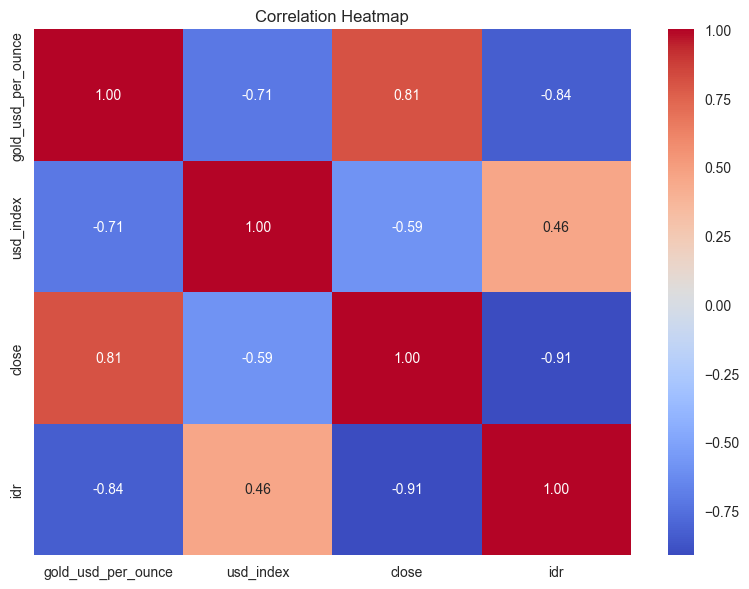

In [136]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_master[
    ["gold_usd_per_ounce", "usd_index", "close", "idr"]
].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Insight EDA

1. Berdasarkan statistik deskriptif seluruh data kurs harian (182 hari), nilai tukar USD/IDR memiliki rata-rata Rp17.681,27 per USD dengan standar deviasi Rp326,10, nilai terendah Rp16.925,62, dan nilai tertinggi Rp18.186,33.

2. Berdasarkan correlation matrix, IHSG memiliki hubungan negatif sangat kuat (−0,91) terhadap USD/IDR, harga emas memiliki hubungan negatif kuat (−0,83), dan USD Index memiliki hubungan positif sedang (+0,44).

3. Dari ketiga variabel, IHSG memiliki hubungan paling kuat dengan USD/IDR, kemudian harga emas, dan terakhir USD Index.

Visualization & Explanatory Analysis

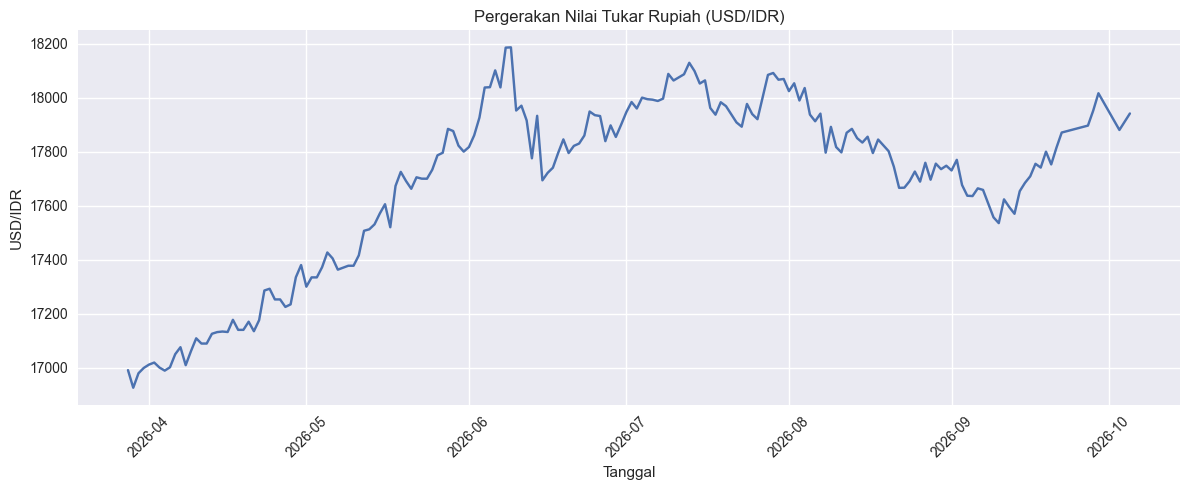

In [137]:
plt.figure(figsize=(12, 5))
plt.plot(df_currency["date"], df_currency["idr"])

plt.title("Pergerakan Nilai Tukar Rupiah (USD/IDR)")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Bagaimana hubungan antara harga emas, USD Index, dan IHSG terhadap pergerakan nilai tukar Rupiah?

Scatter Plot Gold vs USD/IDR

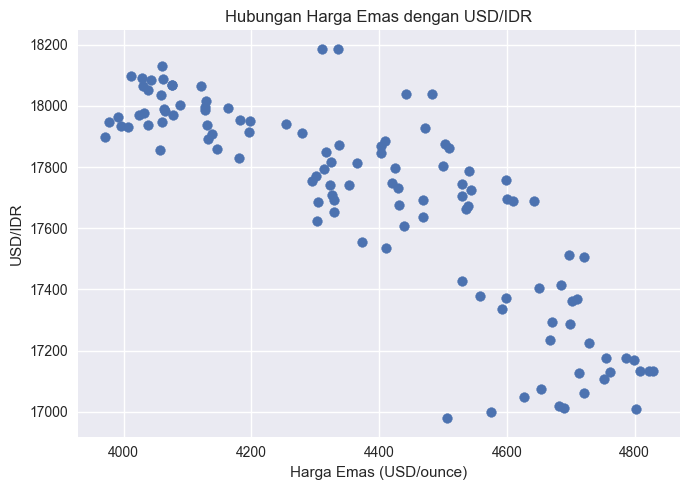

In [138]:
plt.figure(figsize=(7, 5))
plt.scatter(df_master["gold_usd_per_ounce"], df_master["idr"])
plt.title("Hubungan Harga Emas dengan USD/IDR")
plt.xlabel("Harga Emas (USD/ounce)")
plt.ylabel("USD/IDR")
plt.tight_layout()
plt.show()

Scatter Plot USD Index vs USD/IDR

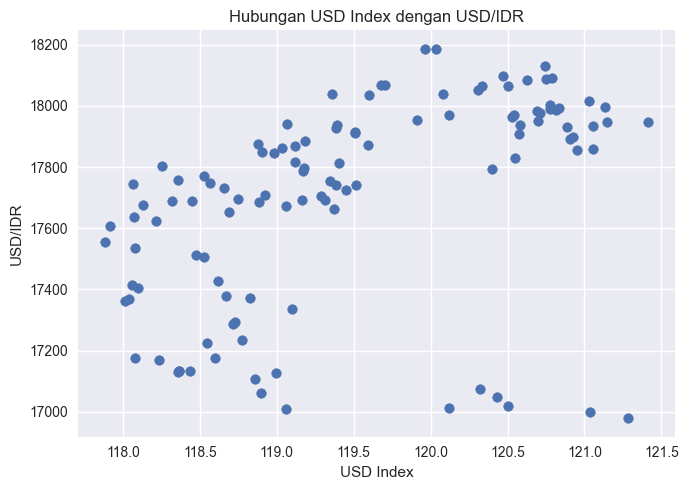

In [139]:
plt.figure(figsize=(7, 5))
plt.scatter(df_master["usd_index"], df_master["idr"])
plt.title("Hubungan USD Index dengan USD/IDR")
plt.xlabel("USD Index")
plt.ylabel("USD/IDR")
plt.tight_layout()
plt.show()

Scatter Plot IHSG vs USD/IDR

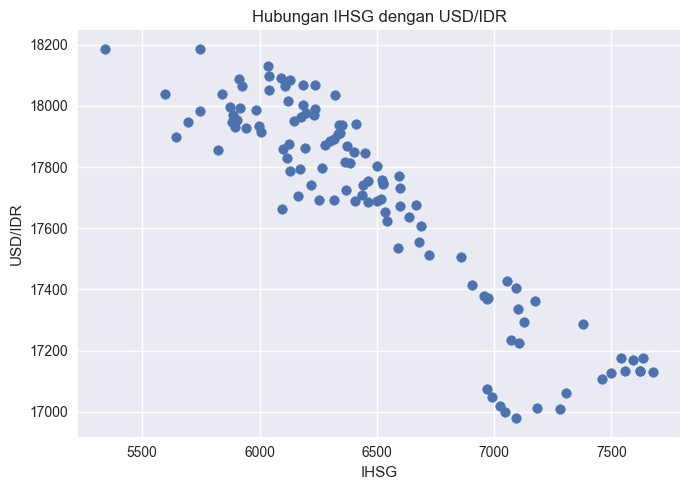

In [140]:
plt.figure(figsize=(7, 5))
plt.scatter(df_master["close"], df_master["idr"])
plt.title("Hubungan IHSG dengan USD/IDR")
plt.xlabel("IHSG")
plt.ylabel("USD/IDR")
plt.tight_layout()
plt.show()

3. Variabel manakah yang memiliki hubungan paling kuat terhadap pergerakan nilai tukar Rupiah?

Correlation Heatmap

Korelasi terhadap USD/IDR

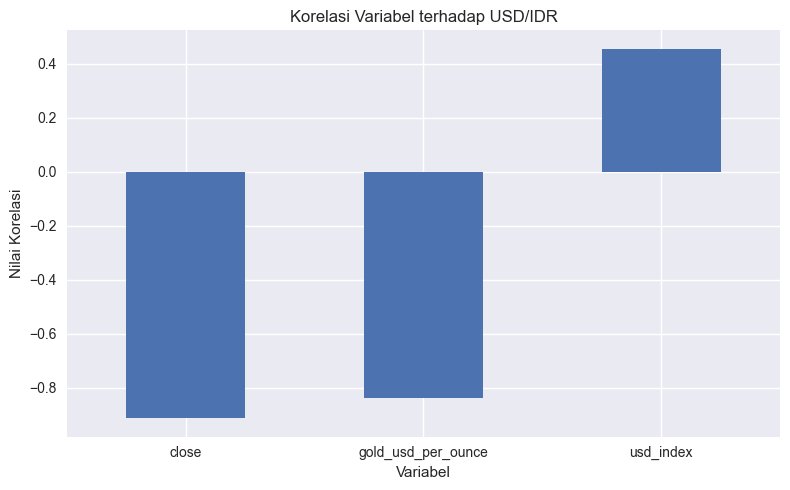

In [141]:
corr_idr = corr["idr"].drop("idr").sort_values()

plt.figure(figsize=(8, 5))
corr_idr.plot(kind="bar")
plt.title("Korelasi Variabel terhadap USD/IDR")
plt.xlabel("Variabel")
plt.ylabel("Nilai Korelasi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight Hasil Visualisasi EDA

1. Nilai tukar Rupiah selama periode pengamatan menunjukkan pergerakan yang cukup fluktuatif, dengan rata-rata Rp17.681,27 per USD, nilai terendah Rp16.925,62, dan nilai tertinggi Rp18.186,33.
2. Pergerakan USD/IDR menunjukkan adanya periode penguatan dan pelemahan Rupiah. Setelah mencapai titik tertinggi pada Juni 2026, nilai tukar sempat menurun sebelum kembali meningkat menjelang akhir periode.
3. Berdasarkan scatter plot dan correlation matrix, IHSG memiliki hubungan negatif sangat kuat (-0,91) terhadap USD/IDR. Harga emas juga memiliki hubungan negatif kuat (-0,83), sedangkan USD Index memiliki hubungan positif sedang (+0,44).
4. Dari ketiga variabel tersebut, IHSG menunjukkan hubungan paling kuat dengan USD/IDR, kemudian harga emas, dan terakhir USD Index.
5. Hasil EDA menunjukkan bahwa IHSG dan harga emas merupakan variabel yang memiliki hubungan paling kuat dengan pergerakan USD/IDR dalam dataset yang dianalisis. Hasil ini selanjutnya dapat digunakan sebagai dasar untuk tahap Machine Learning.

### Analisis Lanjutan

Perubahan Harian USD/IDR

In [142]:
df_master["idr_change"] = df_master["idr"].diff()

print("=== PERUBAHAN HARIAN USD/IDR ===")
display(
    df_master[["date", "idr", "idr_change"]].head(10)
)

=== PERUBAHAN HARIAN USD/IDR ===


,date,idr,idr_change
0,2026-03-30,16979.270486,NaN
1,2026-03-31,16998.895079,19.624593
2,2026-04-01,17011.272551,12.377472
3,2026-04-02,17018.875431,7.602880
4,2026-04-06,17049.849101,30.973670
5,2026-04-07,17075.748413,25.899312
6,2026-04-08,17009.240993,-66.507421
7,2026-04-09,17060.900344,51.659352
8,2026-04-10,17108.653699,47.753354
9,2026-04-13,17125.493379,16.839680


Statistik Perubahan Harian

In [143]:
print("=== STATISTIK PERUBAHAN HARIAN ===")
print(df_master["idr_change"].describe())

=== STATISTIK PERUBAHAN HARIAN ===
count    113.000000
mean       9.177634
std       61.630679
min     -233.908956
25%      -24.722770
50%        8.595021
75%       46.664445
max      160.595010
Name: idr_change, dtype: float64


Perubahan Terbesar

In [144]:
print("=== PERUBAHAN TERBESAR ===")

print("\nPenguatan Rupiah terbesar:")
display(
    df_master.loc[
        df_master["idr_change"].idxmin(),
        ["date", "idr", "idr_change"]
    ]
)

print("\nPelemahan Rupiah terbesar:")
display(
    df_master.loc[
        df_master["idr_change"].idxmax(),
        ["date", "idr", "idr_change"]
    ]
)

=== PERUBAHAN TERBESAR ===

Penguatan Rupiah terbesar:


date          2026-06-10 00:00:00
idr                  17952.416994
idr_change            -233.908956
Name: 44, dtype: object


Pelemahan Rupiah terbesar:


date          2026-05-18 00:00:00
idr                  17673.006755
idr_change              160.59501
Name: 31, dtype: object

Membuat Lag USD/IDR

In [145]:
df_master["idr_lag_1"] = df_master["idr"].shift(1)

print("=== LAG USD/IDR ===")
display(
    df_master[["date", "idr", "idr_lag_1"]].head(10)
)

=== LAG USD/IDR ===


,date,idr,idr_lag_1
0,2026-03-30,16979.270486,NaN
1,2026-03-31,16998.895079,16979.270486
2,2026-04-01,17011.272551,16998.895079
3,2026-04-02,17018.875431,17011.272551
4,2026-04-06,17049.849101,17018.875431
5,2026-04-07,17075.748413,17049.849101
6,2026-04-08,17009.240993,17075.748413
7,2026-04-09,17060.900344,17009.240993
8,2026-04-10,17108.653699,17060.900344
9,2026-04-13,17125.493379,17108.653699


Korelasi Lag dengan USD/IDR

In [146]:
print("=== KORELASI USD/IDR DENGAN LAG 1 HARI ===")

corr_lag = df_master[["idr", "idr_lag_1"]].corr()

print(corr_lag)

=== KORELASI USD/IDR DENGAN LAG 1 HARI ===
                idr  idr_lag_1
idr        1.000000   0.982651
idr_lag_1  0.982651   1.000000


Rolling Mean 7 Hari

In [147]:
df_master["idr_rolling_7"] = df_master["idr"].rolling(window=7).mean()

print("=== ROLLING MEAN USD/IDR 7 HARI ===")
display(
    df_master[["date", "idr", "idr_rolling_7"]].tail(10)
)

=== ROLLING MEAN USD/IDR 7 HARI ===


,date,idr,idr_rolling_7
104,2026-09-11,17623.325305,17629.452551
105,2026-09-14,17653.660626,17612.871888
106,2026-09-15,17684.564493,17614.018082
107,2026-09-16,17708.738636,17624.295189
108,2026-09-17,17755.033365,17645.329028
109,2026-09-18,17740.993700,17671.660075
110,2026-09-21,17814.840838,17711.593852
111,2026-09-22,17870.817523,17746.949883
112,2026-09-28,17951.684356,17789.524702
113,2026-09-29,18016.343107,17836.921647


Visualisasi Rolling Mean

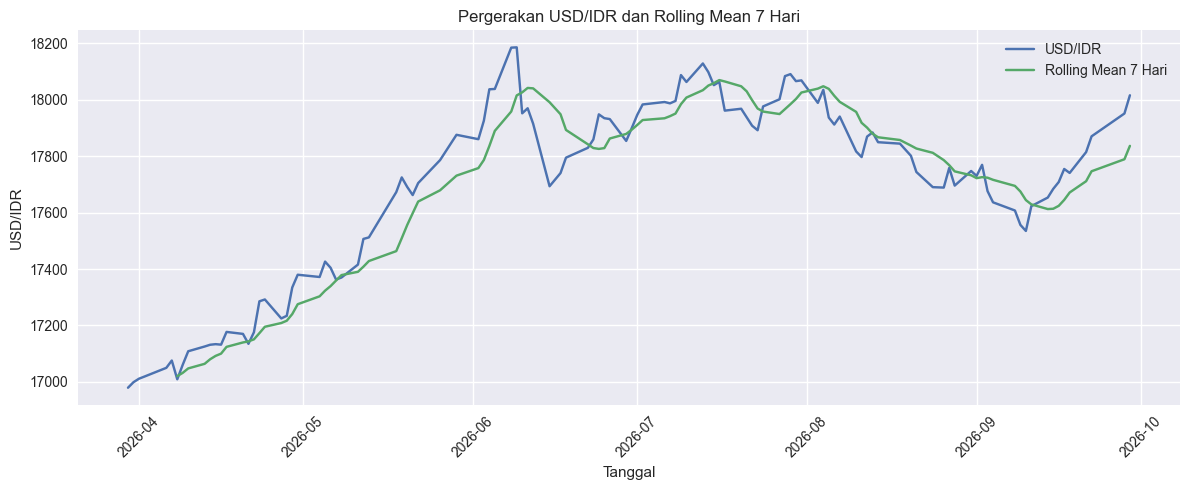

In [148]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_master["date"],
    df_master["idr"],
    label="USD/IDR"
)

plt.plot(
    df_master["date"],
    df_master["idr_rolling_7"],
    label="Rolling Mean 7 Hari"
)

plt.title("Pergerakan USD/IDR dan Rolling Mean 7 Hari")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Analisis arah pergerakan Rupiah

In [149]:
df_master["arah_pergerakan"] = df_master["idr_change"].dropna().apply(
    lambda x: "Naik" if x > 0 else ("Turun" if x < 0 else "Tetap")
)

print("=== JUMLAH HARI BERDASARKAN ARAH PERGERAKAN USD/IDR ===")
print(df_master["arah_pergerakan"].value_counts())

=== JUMLAH HARI BERDASARKAN ARAH PERGERAKAN USD/IDR ===
arah_pergerakan
Naik     68
Turun    45
Name: count, dtype: int64


### Insight Hasil Analisis Lanjutan

1. USD/IDR lebih sering naik, yaitu 68 hari naik dan 45 hari turun.
2. Pergerakan harian cukup fluktuatif, dengan rata-rata perubahan Rp8,03.
3. Rolling mean 7 hari menunjukkan nilai tinggi pada Juni–Agustus, lalu menurun pada September.
4. Korelasi lag-1 0,9828 menunjukkan nilai sebelumnya sangat berkaitan dengan nilai berikutnya.
5. Hasil ini menjadi dasar penggunaan fitur lag dan rolling pada XGBoost.

### Machine Learning — Revisi dan Validasi

Bagian ini memperbaiki tiga hal utama pada pipeline sebelumnya:
1. penyelarasan fitur dengan target satu langkah ke depan,
2. evaluasi terhadap baseline sederhana,
3. validasi dan tuning menggunakan `TimeSeriesSplit` hanya pada data training.

**Definisi prediksi:** pada tanggal *t*, seluruh informasi tanggal *t* dianggap sudah tersedia dan digunakan untuk memprediksi nilai USD/IDR pada tanggal observasi berikutnya (*t+1*). Karena itu, nilai `idr` pada tanggal *t* boleh menjadi fitur. Ini bukan data leakage selama informasi tersebut memang tersedia pada saat prediksi dibuat.

### 1. Membentuk Target dan Fitur Secara Temporal

Pada notebook sebelumnya, `idr_target = idr.shift(-1)` sudah benar untuk target t+1.

Namun ada ketidaktepatan alignment:
- `idr_lag_1 = idr.shift(1)` pada baris t sebenarnya adalah IDR t-1.
- `idr_lag_7 = idr.shift(7)` pada baris t adalah IDR t-7.
- Untuk memprediksi t+1, nilai `idr` saat ini (t) adalah informasi yang sah dan sangat penting.

Karena itu kita pertahankan fitur historis, tetapi tambahkan `idr_current` secara eksplisit agar hubungan waktu jelas.

In [150]:
# TARGET & FEATURE ENGINEERING — ALIGNED FOR t -> t+1
df_ml = df_master.copy().sort_values("date").reset_index(drop=True)

# Target: nilai USD/IDR pada observasi berikutnya
df_ml["idr_target"] = df_ml["idr"].shift(-1)

# Nilai saat ini (t), sah untuk memprediksi t+1
df_ml["idr_current"] = df_ml["idr"]

# Fitur historis
df_ml["idr_lag_1"] = df_ml["idr"].shift(1)
df_ml["idr_lag_7"] = df_ml["idr"].shift(7)
df_ml["idr_rolling_7"] = df_ml["idr"].rolling(window=7).mean()

features = [
    "idr_current",
    "idr_lag_1",
    "idr_lag_7",
    "idr_rolling_7",
    "gold_usd_per_ounce",
    "usd_index",
    "close"
]

df_ml = (
    df_ml[["date"] + features + ["idr_target"]]
    .dropna()
    .reset_index(drop=True)
)

print("=== DATASET MACHINE LEARNING REVISI ===")
print("Jumlah baris :", len(df_ml))
print("Jumlah fitur :", len(features))
display(df_ml.head(10))

=== DATASET MACHINE LEARNING REVISI ===
Jumlah baris : 106
Jumlah fitur : 7


,date,idr_current,idr_lag_1,idr_lag_7,idr_rolling_7,gold_usd_per_ounce,usd_index,close,idr_target
0,2026-04-09,17060.900344,17009.240993,16979.270486,17032.111702,4721.271253,118.8998,7307.588867,17108.653699
1,2026-04-10,17108.653699,17060.900344,16998.895079,17047.791505,4752.487820,118.8552,7458.496094,17125.493379
2,2026-04-13,17125.493379,17108.653699,17011.272551,17064.108766,4712.794303,118.9916,7500.187012,17131.702229
3,2026-04-14,17131.702229,17125.493379,17018.875431,17080.226880,4761.906803,118.3581,7675.951172,17133.796629
4,2026-04-15,17133.796629,17131.702229,17049.849101,17092.219384,4828.303360,118.3623,7623.585938,17132.050469
5,2026-04-16,17132.050469,17133.796629,17075.748413,17100.262535,4822.685759,118.3616,7621.381836,17177.207269
6,2026-04-17,17177.207269,17132.050469,17009.240993,17124.257717,4787.016310,118.0795,7634.003906,17170.200850
7,2026-04-20,17170.200850,17177.207269,17060.900344,17139.872075,4798.510312,118.2374,7594.110840,17135.003383
8,2026-04-21,17135.003383,17170.200850,17108.653699,17143.636315,4807.746857,118.4331,7559.379883,17175.993438
9,2026-04-22,17175.993438,17135.003383,17125.493379,17150.850610,4754.627465,118.6004,7541.611816,17285.753716


In [151]:
# CEK ALIGNMENT — tidak ada fitur yang mengambil nilai masa depan
check_alignment = df_master[["date", "idr"]].copy()
check_alignment["target_t_plus_1"] = check_alignment["idr"].shift(-1)
check_alignment["idr_current"] = check_alignment["idr"]
check_alignment["idr_lag_1"] = check_alignment["idr"].shift(1)
check_alignment["idr_lag_7"] = check_alignment["idr"].shift(7)
check_alignment["rolling_7"] = check_alignment["idr"].rolling(7).mean()

display(check_alignment.head(12))

print("idr_current = nilai t")
print("target_t_plus_1 = nilai t+1")
print("idr_lag_1 = nilai t-1")
print("idr_lag_7 = nilai t-7")
print("rolling_7 = rata-rata 7 observasi sampai t")

,date,idr,target_t_plus_1,idr_current,idr_lag_1,idr_lag_7,rolling_7
0,2026-03-30,16979.270486,16998.895079,16979.270486,NaN,NaN,NaN
1,2026-03-31,16998.895079,17011.272551,16998.895079,16979.270486,NaN,NaN
2,2026-04-01,17011.272551,17018.875431,17011.272551,16998.895079,NaN,NaN
3,2026-04-02,17018.875431,17049.849101,17018.875431,17011.272551,NaN,NaN
4,2026-04-06,17049.849101,17075.748413,17049.849101,17018.875431,NaN,NaN
5,2026-04-07,17075.748413,17009.240993,17075.748413,17049.849101,NaN,NaN
6,2026-04-08,17009.240993,17060.900344,17009.240993,17075.748413,NaN,17020.450294
7,2026-04-09,17060.900344,17108.653699,17060.900344,17009.240993,16979.270486,17032.111702
8,2026-04-10,17108.653699,17125.493379,17108.653699,17060.900344,16998.895079,17047.791505
9,2026-04-13,17125.493379,17131.702229,17125.493379,17108.653699,17011.272551,17064.108766


idr_current = nilai t
target_t_plus_1 = nilai t+1
idr_lag_1 = nilai t-1
idr_lag_7 = nilai t-7
rolling_7 = rata-rata 7 observasi sampai t


### 2. Time-Based Train-Test Split

Data testing tetap berada di periode paling akhir. Tidak digunakan `train_test_split(random_state=...)` karena pengacakan akan merusak urutan temporal.

`random_state` pada XGBoost hanya mengatur proses internal yang bersifat acak; **random_state bukan penyebab data leakage**.

In [152]:
# TIME-BASED TRAIN-TEST SPLIT
split_index = int(len(df_ml) * 0.80)

train = df_ml.iloc[:split_index].copy()
test = df_ml.iloc[split_index:].copy()

X_train = train[features]
y_train = train["idr_target"]
X_test = test[features]
y_test = test["idr_target"]

print("=== TIME-BASED SPLIT ===")
print("Total data :", len(df_ml))
print("Training   :", len(train))
print("Testing    :", len(test))
print("Training   :", train["date"].min(), "sampai", train["date"].max())
print("Testing    :", test["date"].min(), "sampai", test["date"].max())

=== TIME-BASED SPLIT ===
Total data : 106
Training   : 84
Testing    : 22
Training   : 2026-04-09 00:00:00 sampai 2026-08-20 00:00:00
Testing    : 2026-08-21 00:00:00 sampai 2026-09-28 00:00:00


### 3. Baseline Naive

Baseline: **prediksi t+1 = IDR pada t**.

Baseline ini penting karena nilai tukar memiliki persistensi tinggi. Jika model machine learning tidak mengalahkan baseline, fitur/model belum memberikan peningkatan prediksi yang berarti.

In [153]:
# NAIVE BASELINE
y_pred_naive = test["idr_current"]

mae_naive = mean_absolute_error(y_test, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive))
r2_naive = r2_score(y_test, y_pred_naive)

print("=== NAIVE BASELINE ===")
print(f"MAE  : {mae_naive:.2f}")
print(f"RMSE : {rmse_naive:.2f}")
print(f"R²   : {r2_naive:.4f}")

=== NAIVE BASELINE ===
MAE  : 47.28
RMSE : 53.20
R²   : 0.7770


### 4. Linear Regression

Linear Regression digunakan sebagai model pembanding sederhana. Hasil yang lebih rendah daripada XGBoost tidak otomatis menunjukkan kesalahan; hubungan fitur terhadap nilai tukar dapat bersifat non-linear.

In [154]:
# LINEAR REGRESSION
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("=== LINEAR REGRESSION ===")
print(f"MAE  : {mae_lr:.2f}")
print(f"RMSE : {rmse_lr:.2f}")
print(f"R²   : {r2_lr:.4f}")

=== LINEAR REGRESSION ===
MAE  : 46.78
RMSE : 56.70
R²   : 0.7467


### 5. Random Forest

Random Forest digunakan sebagai pembanding model non-linear selain XGBoost.

In [155]:
# RANDOM FOREST
model_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("=== RANDOM FOREST ===")
print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.4f}")

=== RANDOM FOREST ===
MAE  : 74.31
RMSE : 92.72
R²   : 0.3226


### 6. XGBoost Baseline

Model XGBoost digunakan dengan konfigurasi awal, tetapi dilatih menggunakan fitur yang sudah disejajarkan.

In [156]:
# XGBOOST BASELINE
model_xgb = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("=== XGBOOST BASELINE ===")
print(f"MAE  : {mae_xgb:.2f}")
print(f"RMSE : {rmse_xgb:.2f}")
print(f"R²   : {r2_xgb:.4f}")

=== XGBOOST BASELINE ===
MAE  : 58.36
RMSE : 75.99
R²   : 0.5450


### 7. TimeSeriesSplit untuk Tuning

Pada notebook lama `TimeSeriesSplit` baru dibuat, tetapi belum digunakan. Sekarang cross-validation benar-benar digunakan untuk memilih hyperparameter.

Cross-validation hanya dilakukan pada data training. Data testing akhir tetap disimpan dan hanya digunakan untuk evaluasi final.

In [157]:
# TIME SERIES CROSS-VALIDATION
tscv = TimeSeriesSplit(n_splits=5)
print("Jumlah fold TimeSeriesSplit:", tscv.n_splits)

Jumlah fold TimeSeriesSplit: 5


In [158]:
# XGBOOST TUNING DENGAN TIMESERIESPLIT
from sklearn.model_selection import GridSearchCV

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.05],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train, y_train)

print("Best parameters:")
print(grid_xgb.best_params_)
print("Best CV RMSE:")
print(-grid_xgb.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}
Best CV RMSE:
159.85836495791605


In [159]:
# EVALUASI FINAL XGBOOST TERBAIK
best_xgb = grid_xgb.best_estimator_
y_pred_best_xgb = best_xgb.predict(X_test)

mae_best_xgb = mean_absolute_error(y_test, y_pred_best_xgb)
rmse_best_xgb = np.sqrt(mean_squared_error(y_test, y_pred_best_xgb))
r2_best_xgb = r2_score(y_test, y_pred_best_xgb)

print("=== XGBOOST TERBAIK — FINAL TEST ===")
print(f"MAE  : {mae_best_xgb:.2f}")
print(f"RMSE : {rmse_best_xgb:.2f}")
print(f"R²   : {r2_best_xgb:.4f}")

=== XGBOOST TERBAIK — FINAL TEST ===
MAE  : 64.12
RMSE : 80.44
R²   : 0.4902


### 8. Perbandingan Semua Model

Model tidak dipilih hanya berdasarkan R². Untuk regresi, MAE dan RMSE juga diperhatikan. Karena target berada dalam satuan Rupiah, MAE/RMSE lebih mudah diinterpretasikan secara praktis.

In [160]:
# MODEL COMPARISON
hasil_model = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost Baseline",
        "XGBoost Tuned"
    ],
    "MAE": [
        mae_naive, mae_lr, mae_rf, mae_xgb, mae_best_xgb
    ],
    "RMSE": [
        rmse_naive, rmse_lr, rmse_rf, rmse_xgb, rmse_best_xgb
    ],
    "R2": [
        r2_naive, r2_lr, r2_rf, r2_xgb, r2_best_xgb
    ]
}).sort_values("RMSE")

display(hasil_model)

,Model,MAE,RMSE,R2
0,Naive Baseline,47.275385,53.204468,0.776973
1,Linear Regression,46.783893,56.703634,0.746673
3,XGBoost Baseline,58.356761,75.992150,0.545014
4,XGBoost Tuned,64.118302,80.442122,0.490167
2,Random Forest,74.308941,92.721784,0.322633


In [161]:
# PEMERIKSAAN TERHADAP NAIVE BASELINE
print("=== PEMERIKSAAN TERHADAP NAIVE BASELINE ===")

for model_name in [
    "Linear Regression",
    "Random Forest",
    "XGBoost Baseline",
    "XGBoost Tuned"
]:
    row = hasil_model[hasil_model["Model"] == model_name].iloc[0]

    print(f"\n{model_name}")
    print("  RMSE lebih baik :", row["RMSE"] < rmse_naive)
    print("  MAE lebih baik  :", row["MAE"] < mae_naive)
    print("  R² lebih baik   :", row["R2"] > r2_naive)

=== PEMERIKSAAN TERHADAP NAIVE BASELINE ===

Linear Regression
  RMSE lebih baik : False
  MAE lebih baik  : True
  R² lebih baik   : False

Random Forest
  RMSE lebih baik : False
  MAE lebih baik  : False
  R² lebih baik   : False

XGBoost Baseline
  RMSE lebih baik : False
  MAE lebih baik  : False
  R² lebih baik   : False

XGBoost Tuned
  RMSE lebih baik : False
  MAE lebih baik  : False
  R² lebih baik   : False


### 9. Feature Importance XGBoost

Feature importance menjelaskan kontribusi relatif fitur terhadap model. Nilainya **bukan koefisien sebab-akibat**.

,Feature,Importance
0,idr_current,0.539506
2,idr_lag_7,0.250130
3,idr_rolling_7,0.108577
6,close,0.072557
5,usd_index,0.018414
1,idr_lag_1,0.005587
4,gold_usd_per_ounce,0.005230


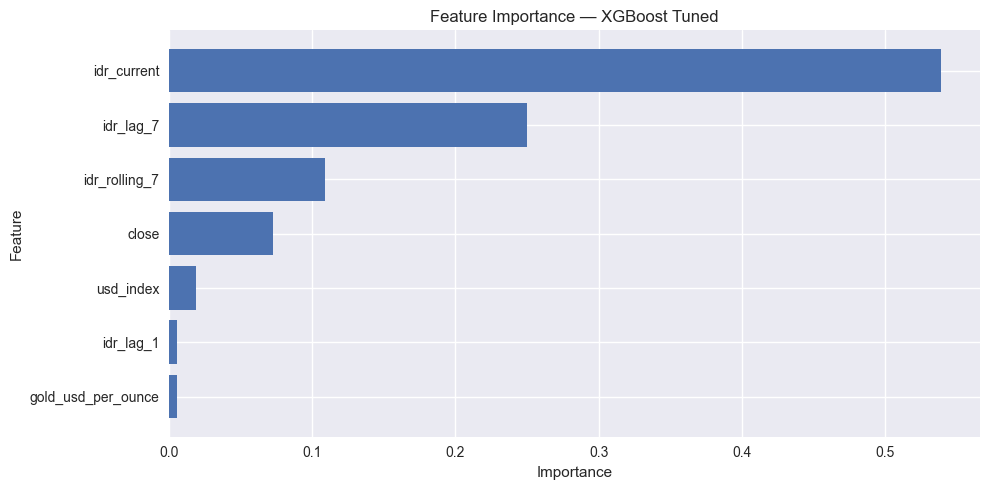

In [162]:
# FEATURE IMPORTANCE
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_xgb.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance — XGBoost Tuned")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [163]:
# OPTIONAL: PERMUTATION IMPORTANCE PADA DATA TEST
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_xgb,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": features,
    "Importance_Mean": perm.importances_mean,
    "Importance_STD": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(perm_df)

,Feature,Importance_Mean,Importance_STD
0,idr_current,31.321256,7.592786
6,close,10.448056,2.509626
5,usd_index,3.597377,1.273459
1,idr_lag_1,0.029873,0.053775
3,idr_rolling_7,0.000000,0.000000
2,idr_lag_7,-0.124870,0.134786
4,gold_usd_per_ounce,-1.078865,0.700207


### pertanyaan

4. Seberapa baik model machine learning dapat memprediksi nilai tukar Rupiah periode berikutnya?

### 10. Hasil Prediksi dan Visualisasi

,Tanggal,Aktual,Naive,Linear_Regression,Random_Forest,XGBoost
84,2026-08-21,17690.577065,17744.323497,17720.433020,17789.180761,17761.455078
85,2026-08-24,17689.034189,17690.577065,17710.339090,17747.675864,17731.085938
86,2026-08-26,17758.885983,17689.034189,17736.692770,17749.506133,17759.615234
87,2026-08-27,17696.095190,17758.885983,17770.115093,17786.645701,17761.455078
88,2026-08-28,17747.904806,17696.095190,17735.433611,17746.345289,17729.634766
89,2026-08-31,17730.426014,17747.904806,17724.913104,17789.656494,17757.968750
90,2026-09-01,17769.725266,17730.426014,17707.222517,17778.508130,17745.246094
91,2026-09-02,17676.541136,17769.725266,17698.090817,17814.771974,17757.968750
92,2026-09-03,17636.798891,17676.541136,17622.864644,17753.743569,17731.085938
93,2026-09-04,17607.796495,17636.798891,17600.980498,17753.674080,17731.085938


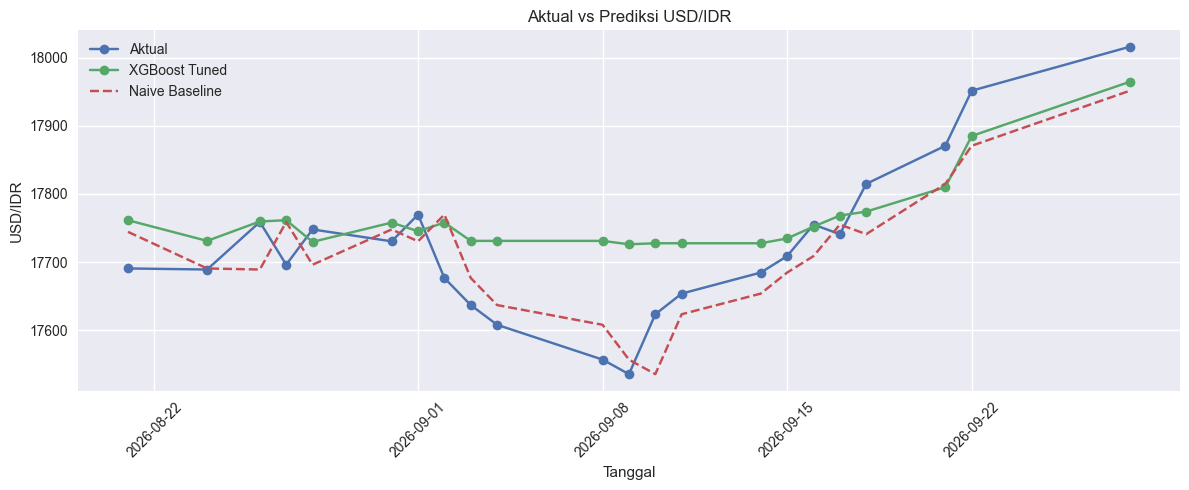

In [164]:
# HASIL PREDIKSI
hasil_prediksi = pd.DataFrame({
    "Tanggal": test["date"].values,
    "Aktual": y_test.values,
    "Naive": y_pred_naive,
    "Linear_Regression": y_pred_lr,
    "Random_Forest": y_pred_rf,
    "XGBoost": y_pred_best_xgb
})

display(hasil_prediksi.head(10))

plt.figure(figsize=(12, 5))
plt.plot(hasil_prediksi["Tanggal"], hasil_prediksi["Aktual"],
         marker="o", label="Aktual")
plt.plot(hasil_prediksi["Tanggal"], hasil_prediksi["XGBoost"],
         marker="o", label="XGBoost Tuned")
plt.plot(hasil_prediksi["Tanggal"], hasil_prediksi["Naive"],
         linestyle="--", label="Naive Baseline")

plt.title("Aktual vs Prediksi USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 11. Pemeriksaan Data Leakage

**Tidak dianggap leakage:**
- `idr_current` pada t untuk memprediksi t+1, jika nilai t sudah tersedia ketika prediksi dibuat.
- `idr_lag_1`, `idr_lag_7`, dan rolling mean yang hanya memakai data sampai t.
- `random_state=42` pada model.

**Berpotensi menjadi leakage:**
- menggunakan `idr_target` atau nilai t+1 sebagai fitur,
- melakukan random train-test split pada time series,
- melakukan preprocessing yang belajar dari seluruh dataset sebelum split,
- menggunakan data eksternal yang timestamp-nya ternyata baru tersedia setelah target t+1.

Karena dataset menggunakan tanggal tanpa timestamp intrahari, waktu ketersediaan aktual `gold_usd_per_ounce`, `usd_index`, dan `close` harus disesuaikan dengan definisi waktu prediksi penelitian.

In [ ]:
# AUTOMATIC LEAKAGE / ORDER CHECK
assert "idr_target" not in features
assert train["date"].max() < test["date"].min()

print("OK: target tidak masuk sebagai fitur.")
print("OK: seluruh data training berada sebelum data testing.")

OK: target tidak masuk sebagai fitur.
OK: seluruh data training berada sebelum data testing.


: 

### 12. Kesimpulan Evaluasi Model

Notebook lama mempunyai dua masalah metodologis utama:

1. **Alignment fitur kurang tepat.** `idr_target` adalah t+1, tetapi `idr_lag_1` pada baris t adalah t-1. Nilai IDR t sendiri belum dimasukkan secara eksplisit sebagai fitur. Ini bukan leakage, tetapi formulasi fitur kurang optimal untuk prediksi satu langkah ke depan.
2. **TimeSeriesSplit dibuat tetapi belum digunakan.** Notebook lama hanya membuat objek `TimeSeriesSplit`; model XGBoost tetap dilatih langsung pada seluruh training tanpa CV untuk tuning.

Hasil notebook lama:
- XGBoost awal: MAE 85,16; RMSE 107,23; R² 0,0942.
- XGBoost tuning manual: MAE 78,00; RMSE 99,84; R² 0,2146.

Hasil tersebut menunjukkan tuning manual memperbaiki performa test set lama, tetapi belum membuktikan bahwa XGBoost adalah model terbaik. Setelah notebook revisi dijalankan, keputusan model harus berdasarkan perbandingan Naive, Linear Regression, Random Forest, dan XGBoost pada test set yang sama.

**R² rendah tidak boleh langsung dianggap sebagai bukti model salah.** Jika model tetap tidak mengalahkan naive baseline setelah alignment diperbaiki dan validasi time series dilakukan, kemungkinan masalah lebih besar berada pada informasi prediktif fitur dan karakteristik target USD/IDR yang memang sulit diprediksi.

### Insight Machine Learning


1. Pola pergerakan USD/IDR. Selama periode pengamatan, nilai tukar USD/IDR lebih sering melemah (68 hari naik) dibanding menguat (45 hari turun), dengan rata-rata perubahan harian sekitar Rp8,03. Berdasarkan rolling mean 7 hari, kurs berada pada level tinggi periode Juni–Agustus lalu menurun pada September. Nilai tukar ini sangat persisten, terlihat dari korelasi lag-1 sebesar 0,98 yang berarti nilai hari sebelumnya hampir selalu mencerminkan nilai hari berikutnya.

2. Hubungan harga emas, USD Index, dan IHSG terhadap USD/IDR. Ketiga variabel menunjukkan hubungan yang bervariasi. IHSG berkorelasi negatif sangat kuat dengan USD/IDR (−0,91), harga emas juga berkorelasi negatif (−0,84), sedangkan USD Index berkorelasi positif moderat (0,46). Artinya, ketika IHSG atau harga emas naik, kurs USD/IDR cenderung turun (rupiah menguat), sementara penguatan USD Index cenderung diikuti naiknya USD/IDR.

3. Variabel paling dominan. IHSG merupakan variabel dengan hubungan terkuat terhadap USD/IDR (korelasi −0,91), lebih kuat dibanding harga emas (−0,84) maupun USD Index (0,46).

4. Kinerja model machine learning. Data dibagi secara temporal menjadi 84 data latih dan 22 data uji agar informasi masa depan tidak bocor ke proses pelatihan. Berdasarkan perbandingan seluruh model, Naive Baseline justru menghasilkan error terkecil (RMSE 53,20; R² 0,78), disusul Linear Regression (RMSE 56,70). Model yang lebih kompleks memberi hasil lebih buruk: XGBoost Baseline (RMSE 75,99), XGBoost Tuned (RMSE 80,44; MAE 64,12; R² 0,49), dan Random Forest (RMSE 92,72). Tuning hyperparameter tidak meningkatkan performa XGBoost, bahkan sedikit menurunkannya.

5. Feature importance. Pada model XGBoost, fitur paling dominan adalah idr_current (importance 0,54), diikuti idr_lag_7 (0,25) dan idr_rolling_7 (0,11), sedangkan close, usd_index, idr_lag_1, dan gold_usd_per_ounce berkontribusi kecil. Model lebih banyak memanfaatkan level dan pola historis USD/IDR itu sendiri dibanding variabel eksternal.

6. Interpretasi keseluruhan. Prediksi XGBoost cukup mengikuti pola umum pergerakan kurs, tetapi masih lemah dalam menangkap perubahan tajam. Fakta bahwa tidak ada model machine learning yang mengalahkan Naive Baseline menunjukkan bahwa USD/IDR harian bersifat sangat persisten, sehingga nilai hari ini sudah menjadi prediktor terbaik untuk hari berikutnya. Dengan demikian, pertanyaan bisnis keempat terjawab: model mampu memprediksi dengan rata-rata kesalahan sekitar Rp64–80, namun pada periode ini pendekatan sederhana tetap paling akurat.



### Conclusion


Langkah - Langkah yang telah dilakukan
1. Merangkum hasil utama analisis nilai tukar USD/IDR selama periode penelitian.
2. Merangkum hubungan antarvariabel antara USD/IDR, harga emas, USD Index, dan IHSG berdasarkan matriks korelasi.
3. Merangkum hasil analisis lanjutan berdasarkan pola dan hubungan yang ditemukan pada data.
4. Membandingkan kinerja beberapa model machine learning — Naive Baseline, Linear Regression, Random Forest, XGBoost Baseline, dan XGBoost Tuned — berdasarkan MAE, RMSE, dan R², dengan
5. pembagian data secara temporal (time-based split) untuk menghindari data leakage.
6. Merangkum fitur yang paling berpengaruh berdasarkan Feature Importance model XGBoost.
7.  Menjawab seluruh pertanyaan penelitian berdasarkan hasil analisis yang telah dilakukan.
8. Menjelaskan keterbatasan hasil prediksi bahwa model masih kurang mampu menangkap perubahan nilai tukar yang terjadi secara tiba-tiba.